# 01 — Demographic Analysis

## Healthcare Operations Intelligence Ireland

**Period:** 2020–2025  
**Geographic scope:** Ireland  
**Data sources:** CSO and Eurostat

This notebook explores demographic changes among older people in Ireland and examines functional limitations across different age groups.



## 1. Project Objective

The objective of this analysis is to understand the growth of the older population in Ireland and explore how functional limitations vary across age groups.

The analysis aims to demonstrate why age alone is not sufficient to determine an individual's need for long-term care services.


## 2. Import Libraries

In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 3. Load Dataset

In [3]:
pd_cso_population_age_2020_2025 = pd.read_csv('../data/raw/cso_population_age_2020_2025.csv')
pd_eurostat_functional_limitations_2020_2025 = pd.read_csv('../data/raw/eurostat_functional_limitations_2020_2025.csv')

## 4. Initial Data Exploration

In [4]:
pd_cso_population_age_2020_2025.info()

<class 'pandas.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   STATISTIC Label  35 non-null     str    
 1   Year             35 non-null     int64  
 2   Age Group        35 non-null     str    
 3   Sex              35 non-null     str    
 4   UNIT             35 non-null     str    
 5   VALUE            35 non-null     float64
dtypes: float64(1), int64(1), str(4)
memory usage: 1.8 KB


In [5]:
pd_eurostat_functional_limitations_2020_2025.info()

<class 'pandas.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 25 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   STRUCTURE                               54 non-null     str    
 1   STRUCTURE_ID                            54 non-null     str    
 2   STRUCTURE_NAME                          54 non-null     str    
 3   freq                                    54 non-null     str    
 4   Time frequency                          54 non-null     str    
 5   deg_urb                                 54 non-null     str    
 6   Degree of urbanisation                  54 non-null     str    
 7   lev_limit                               54 non-null     str    
 8   Level of activity limitation            36 non-null     str    
 9   sex                                     54 non-null     str    
 10  Sex                                     54 non-null     str    
 11  age   

## 4. Initial Data Exploration

### 4.1. Population Dataset

Investigate the available years, age groups and sex categories.

### 4.2. Functional Limitations Dataset

Investigate the available years, age groups and levels of activity limitation.


In [6]:
years = pd_cso_population_age_2020_2025['Year'].unique()
age_group = pd_cso_population_age_2020_2025['Age Group'].unique()
sex_group = pd_cso_population_age_2020_2025['Sex'].unique()

print("Years in the dataset:", years)
print("Age groups in the dataset:", age_group)
print("Sex groups in the dataset:", sex_group)

Years in the dataset: [2020 2021 2022 2023 2024 2025 2026]
Age groups in the dataset: <StringArray>
[    '65 - 69 years',     '70 - 74 years',     '75 - 79 years',
     '80 - 84 years', '85 years and over']
Length: 5, dtype: str
Sex groups in the dataset: <StringArray>
['Both sexes']
Length: 1, dtype: str


In [7]:
years_eurostat = pd_eurostat_functional_limitations_2020_2025['TIME_PERIOD'].unique()
age_group_eurostat = pd_eurostat_functional_limitations_2020_2025['Age class'].unique()
code_lev_limit = pd_eurostat_functional_limitations_2020_2025['lev_limit'].unique()
level_of_activity_limit = pd_eurostat_functional_limitations_2020_2025['Level of activity limitation'].unique()


print("Years in the Eurostat dataset:", years_eurostat)
print("Age groups in the Eurostat dataset:", age_group_eurostat)
print("Code levels in the Eurostat dataset:", code_lev_limit)
print("Level of activity limits in the Eurostat dataset:", level_of_activity_limit)

Years in the Eurostat dataset: [2020 2021 2022 2023 2024 2025]
Age groups in the Eurostat dataset: <StringArray>
['From 65 to 74 years', 'From 75 to 84 years', '85 years or over']
Length: 3, dtype: str
Code levels in the Eurostat dataset: <StringArray>
['NONE', 'SEV', 'SOME']
Length: 3, dtype: str
Level of activity limits in the Eurostat dataset: <StringArray>
[nan, 'Severe', 'Some']
Length: 3, dtype: str



### 4.3. Data Structure Validation

Verify whether the datasets contain the expected number of observations for each year and age group.


In [8]:
years_group = pd_cso_population_age_2020_2025.groupby('Year')['STATISTIC Label'].value_counts().unstack(fill_value=0)
age_group_counts = pd_cso_population_age_2020_2025.groupby('Age Group')['STATISTIC Label'].value_counts().unstack(fill_value=0)

print("Counts of STATISTIC Label by Year:")
print(years_group)

print("Counts of STATISTIC Label by Age Group:")
print(age_group_counts)

Counts of STATISTIC Label by Year:
STATISTIC Label  Population Estimates (Persons in April)
Year                                                    
2020                                                   5
2021                                                   5
2022                                                   5
2023                                                   5
2024                                                   5
2025                                                   5
2026                                                   5
Counts of STATISTIC Label by Age Group:
STATISTIC Label    Population Estimates (Persons in April)
Age Group                                                 
65 - 69 years                                            7
70 - 74 years                                            7
75 - 79 years                                            7
80 - 84 years                                            7
85 years and over                                        7

In [9]:
years_group_eurostat = pd_eurostat_functional_limitations_2020_2025.groupby('TIME_PERIOD')['lev_limit'].value_counts().unstack(fill_value=0)
age_group_counts_eurostat = pd_eurostat_functional_limitations_2020_2025.groupby('Age class')['lev_limit'].value_counts().unstack(fill_value=0)

print("Counts of Level of activity limitation by Year in Eurostat dataset:")
print(years_group_eurostat) 
print("Counts of Level of activity limitation by Age class in Eurostat dataset:")
print(age_group_counts_eurostat)

Counts of Level of activity limitation by Year in Eurostat dataset:
lev_limit    NONE  SEV  SOME
TIME_PERIOD                 
2020            3    3     3
2021            3    3     3
2022            3    3     3
2023            3    3     3
2024            3    3     3
2025            3    3     3
Counts of Level of activity limitation by Age class in Eurostat dataset:
lev_limit            NONE  SEV  SOME
Age class                           
85 years or over        6    6     6
From 65 to 74 years     6    6     6
From 75 to 84 years     6    6     6



### 4.4. Initial Data Validation

The Eurostat dataset contains 54 observations, covering six years (2020–2025), three age groups and three levels of activity limitation.

Each year and age group combination contains the three expected categories:

- NONE: No activity limitations
- SOME: Some activity limitations
- SEV: Severe activity limitations

The dataset structure is consistent with the expected number of observations. Further checks are required to identify duplicate records and assess data quality.


## 5. Data Cleaning and Preparation

### 5.1. Column Name Standardization

The original column names contain inconsistent capitalization, spaces and naming conventions.

To improve readability and maintain consistency, column names will be standardized using snake_case.

Original raw files will remain unchanged. All transformations will be performed on DataFrame copies.


In [10]:
cso_population_age_clean = pd_cso_population_age_2020_2025.copy()

cso_population_age_clean.columns

Index(['STATISTIC Label', 'Year', 'Age Group', 'Sex', 'UNIT', 'VALUE'],
      dtype='str')

In [11]:
cso_population_age_clean = cso_population_age_clean.rename(columns={
    'STATISTIC Label': 'statistic_label',
    'Year': 'year',
    'Age Group': 'age_group',
    'Sex': 'sex',
    'UNIT': 'unit',
    'VALUE': 'value'
})

cso_population_age_clean.columns

Index(['statistic_label', 'year', 'age_group', 'sex', 'unit', 'value'],
      dtype='str')

In [12]:
cso_population_age_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   statistic_label  35 non-null     str    
 1   year             35 non-null     int64  
 2   age_group        35 non-null     str    
 3   sex              35 non-null     str    
 4   unit             35 non-null     str    
 5   value            35 non-null     float64
dtypes: float64(1), int64(1), str(4)
memory usage: 1.8 KB


### 5.2. Eurostat Column Selection

The Eurostat dataset contains 25 columns, including metadata, codes, descriptions and observation values.

For this analysis, only the variables relevant to age groups, functional limitations, percentages and data quality will be retained.

The original dataset will remain unchanged. A cleaned copy will be created for further analysis.


In [13]:
pd_eurostat_functional_limitations_clean = pd_eurostat_functional_limitations_2020_2025.copy()

pd_eurostat_functional_limitations_clean.columns

Index(['STRUCTURE', 'STRUCTURE_ID', 'STRUCTURE_NAME', 'freq', 'Time frequency',
       'deg_urb', 'Degree of urbanisation', 'lev_limit',
       'Level of activity limitation', 'sex', 'Sex', 'age', 'Age class',
       'unit', 'Unit of measure', 'geo', 'Geopolitical entity (reporting)',
       'TIME_PERIOD', 'Time', 'OBS_VALUE', 'Observation value', 'OBS_FLAG',
       'Observation status (Flag) V2 structure', 'CONF_STATUS',
       'Confidentiality status (flag)'],
      dtype='str')

In [14]:
pd_eurostat_functional_limitations_clean = pd_eurostat_functional_limitations_clean.rename(columns={
    'STRUCTURE': 'structure',
    'STRUCTURE_ID': 'structure_id',
    'STRUCTURE_NAME': 'structure_name',
    'freq': 'frequency',
    'Time frequency': 'time_frequency',
    'deg_urb': 'deg_urb',
    'Degree of urbanisation': 'degree_of_urbanisation',
    'lev_limit': 'level_limit',
    'Level of activity limitation': 'level_of_activity_limitation',
    'sex': 'sex',
    'Sex': 'sex_group',
    'age':'age_group',
    'Age class':'age_class',
    'unit': 'unit',
    'Unit of measure': 'unit_of_measure',
    'geo': 'geo',
    'Geopolitical entity (reporting)': 'geopolitical_entity',
    'TIME_PERIOD': 'time_period',
    'Time': 'time',
    'OBS_VALUE': 'obs_value',
    'Observation value': 'observation_value',
    'OBS_FLAG': 'obs_flag',
    'Observation status (Flag) V2 structure': 'observation_status_flag',
    'CONF_STATUS': 'conf_status',
    'Confidentiality status (flag)': 'confidentiality_status_flag'
    
})

pd_eurostat_functional_limitations_clean.columns

Index(['structure', 'structure_id', 'structure_name', 'frequency',
       'time_frequency', 'deg_urb', 'degree_of_urbanisation', 'level_limit',
       'level_of_activity_limitation', 'sex', 'sex_group', 'age_group',
       'age_class', 'unit', 'unit_of_measure', 'geo', 'geopolitical_entity',
       'time_period', 'time', 'obs_value', 'observation_value', 'obs_flag',
       'observation_status_flag', 'conf_status',
       'confidentiality_status_flag'],
      dtype='str')

In [15]:
pd_eurostat_functional_limitations_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 25 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   structure                     54 non-null     str    
 1   structure_id                  54 non-null     str    
 2   structure_name                54 non-null     str    
 3   frequency                     54 non-null     str    
 4   time_frequency                54 non-null     str    
 5   deg_urb                       54 non-null     str    
 6   degree_of_urbanisation        54 non-null     str    
 7   level_limit                   54 non-null     str    
 8   level_of_activity_limitation  36 non-null     str    
 9   sex                           54 non-null     str    
 10  sex_group                     54 non-null     str    
 11  age_group                     54 non-null     str    
 12  age_class                     54 non-null     str    
 13  unit              

### 5.3. Column Selection

Select the variables required for the functional limitations analysis.

The original dataset will be preserved, and the selected variables will be stored in a separate DataFrame.


In [16]:
eurostat_functional_clean = pd_eurostat_functional_limitations_clean[
    [
        'time_period', 
        'age_class', 
        'level_limit', 
        'obs_value', 
        'sex', 
        'geo', 
        'deg_urb', 
        'obs_flag'
    ]
].copy()

eurostat_functional_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   time_period  54 non-null     int64  
 1   age_class    54 non-null     str    
 2   level_limit  54 non-null     str    
 3   obs_value    54 non-null     float64
 4   sex          54 non-null     str    
 5   geo          54 non-null     str    
 6   deg_urb      54 non-null     str    
 7   obs_flag     9 non-null      str    
dtypes: float64(1), int64(1), str(6)
memory usage: 3.5 KB


In [17]:
eurostat_functional_clean.head(10)

,time_period,age_class,level_limit,obs_value,sex,geo,deg_urb,obs_flag
0,2020,From 65 to 74 years,NONE,68.1,T,IE,TOTAL,b
1,2021,From 65 to 74 years,NONE,70.3,T,IE,TOTAL,NaN
2,2022,From 65 to 74 years,NONE,62.6,T,IE,TOTAL,NaN
3,2023,From 65 to 74 years,NONE,66.4,T,IE,TOTAL,NaN
4,2024,From 65 to 74 years,NONE,67.6,T,IE,TOTAL,NaN
5,2025,From 65 to 74 years,NONE,67.1,T,IE,TOTAL,NaN
6,2020,From 75 to 84 years,NONE,54.1,T,IE,TOTAL,b
7,2021,From 75 to 84 years,NONE,61.6,T,IE,TOTAL,NaN
8,2022,From 75 to 84 years,NONE,57.1,T,IE,TOTAL,NaN
9,2023,From 75 to 84 years,NONE,54.5,T,IE,TOTAL,NaN


### 5.4. Data Quality Assessment

Verify the consistency of the selected variables, including country, sex, urbanisation and observation flags.

In [18]:
geo_verification = eurostat_functional_clean['geo'].unique()
sex_verification = eurostat_functional_clean['sex'].unique()
deg_urb_verification = eurostat_functional_clean['deg_urb'].unique()

print("Unique values in 'geo' column:", geo_verification)
print("Unique values in 'sex' column:", sex_verification)
print("Unique values in 'deg_urb' column:", deg_urb_verification)

Unique values in 'geo' column: <StringArray>
['IE']
Length: 1, dtype: str
Unique values in 'sex' column: <StringArray>
['T']
Length: 1, dtype: str
Unique values in 'deg_urb' column: <StringArray>
['TOTAL']
Length: 1, dtype: str


In [19]:
obs_flag_verification = eurostat_functional_clean['obs_flag'].value_counts(dropna=False)
print("Value counts in 'obs_flag' column:", obs_flag_verification)

Value counts in 'obs_flag' column: obs_flag
NaN    45
b       9
Name: count, dtype: int64


In [20]:
eurostat_functional_clean['obs_value'].describe()

count    54.000000
mean     33.337037
std      18.877953
min       7.100000
25%      20.450000
50%      29.600000
75%      42.650000
max      70.300000
Name: obs_value, dtype: float64


### Initial Data Quality Findings

- All records refer to Ireland (`IE`).
- The dataset covers both sexes (`T`) and all urbanisation categories (`TOTAL`).
- Nine observations contain the flag `b`, indicating a break in time series.
- The flag requires caution when comparing observations over time.
- Descriptive statistics were calculated, but the overall mean is not interpreted because the dataset combines different age groups and limitation categories.

### 5.5. Observation Flags Investigation

Investigate observations containing special flags to understand potential breaks in the time series.

In [21]:
eurostat_functional_clean.loc[
    eurostat_functional_clean['obs_flag'].notna() 
]

,time_period,age_class,level_limit,obs_value,sex,geo,deg_urb,obs_flag
0,2020,From 65 to 74 years,NONE,68.1,T,IE,TOTAL,b
6,2020,From 75 to 84 years,NONE,54.1,T,IE,TOTAL,b
12,2020,85 years or over,NONE,40.3,T,IE,TOTAL,b
18,2020,From 65 to 74 years,SEV,8.7,T,IE,TOTAL,b
24,2020,From 75 to 84 years,SEV,11.5,T,IE,TOTAL,b
30,2020,85 years or over,SEV,23.7,T,IE,TOTAL,b
36,2020,From 65 to 74 years,SOME,23.2,T,IE,TOTAL,b
42,2020,From 75 to 84 years,SOME,34.5,T,IE,TOTAL,b
48,2020,85 years or over,SOME,36.1,T,IE,TOTAL,b


In [22]:
time_period_group = eurostat_functional_clean.groupby('time_period')['obs_flag'].count()

print("Counts of obs_flag by time_period:")
print(time_period_group)

Counts of obs_flag by time_period:
time_period
2020    9
2021    0
2022    0
2023    0
2024    0
2025    0
Name: obs_flag, dtype: int64


### Observation Flags — Findings

All nine observations flagged with `b` belong to 2020.

The flag appears across all three age groups and all three activity limitation categories.

This indicates a break in the time series affecting the 2020 observations.

The observations will be retained in the dataset, but comparisons between 2020 and subsequent years will be interpreted with caution.


### 5.6. Duplicate Records Check

In [23]:
duplicates = eurostat_functional_clean.duplicated().sum()

print("Number of duplicated rows in eurostat_functional_clean:", duplicates)

Number of duplicated rows in eurostat_functional_clean: 0


In [24]:
duplicates_rows = eurostat_functional_clean.duplicated(
    subset=['time_period', 'age_class', 'level_limit'],
    keep=False
)

print("Number of duplicated rows based on time_period, age_class, and level_limit:", duplicates_rows.sum())

Number of duplicated rows based on time_period, age_class, and level_limit: 0


### Duplicate Records Check — Findings

No complete duplicate rows were identified in the Eurostat dataset.

No duplicate combinations were found across `time_period`, `age_class` and `level_limit`.

All 54 observations represent unique combinations of year, age group and activity limitation level.


In [25]:
duplicates_cso = cso_population_age_clean.duplicated().sum()

print("Number of duplicated rows in cso_population_age_clean:", duplicates_cso)

Number of duplicated rows in cso_population_age_clean: 0


In [26]:
duplicates_rows_cso = cso_population_age_clean.duplicated(
    subset=['year', 'age_group'],
    keep=False
).sum()

print("Number of duplicated rows based on year and age_group in cso_population_age_clean:", duplicates_rows_cso)

Number of duplicated rows based on year and age_group in cso_population_age_clean: 0


### Duplicate Records Check — Findings

**CSO Dataset**
- No complete duplicate rows were identified.
- No duplicate combinations of `year` and `age_group` were found.

**Eurostat Dataset**
- No complete duplicate rows were identified.
- No duplicate combinations of `time_period`, `age_class` and `level_limit` were found.

Both datasets passed the initial duplicate records assessment.


### Age Group Aggregation

To ensure consistency between the CSO population dataset and the Eurostat functional limitations dataset, the original CSO age groups will be aggregated into three broader age categories.

The aggregation will follow these rules:

| Original CSO age groups | New age group |
|---|---|
| 65–69 years + 70–74 years | 65–74 years |
| 75–79 years + 80–84 years | 75–84 years |
| 85 years and over | 85 years and over |

Population values from the original age groups will be summed separately for each year (2020–2025).

**Methodological approach:**

- Group records by year and the new age category.
- Sum population values within each group.
- Preserve the original dataset and create a separate aggregated dataset.

This transformation will provide a consistent age-group structure for comparing population estimates with Eurostat data on functional limitations.

In [27]:
cso_population_analysis = cso_population_age_clean.loc[
    cso_population_age_clean['year'].between(2020, 2025)
].copy()

cso_population_analysis['age_group_new'] = (
    cso_population_analysis['age_group'].replace({
        '65 - 69 years': '65–74 years',
        '70 - 74 years': '65–74 years',
        '75 - 79 years': '75–84 years',
        '80 - 84 years': '75–84 years',
        '85 years and over': '85 years and over'
    })
)

age_group_aggregated =(cso_population_analysis.groupby(
    ['year', 'age_group_new'], as_index=False)['value']
    .sum()
    .rename(columns={'value': 'population'})
)

age_group_aggregated.sort_values(
    ['year', 'age_group_new']
)

,year,age_group_new,population
0,2020,65–74 years,421.2
1,2020,75–84 years,229.3
2,2020,85 years and over,75.6
3,2021,65–74 years,430.3
4,2021,75–84 years,239.6
5,2021,85 years and over,77.5
6,2022,65–74 years,445.2
7,2022,75–84 years,251.8
8,2022,85 years and over,84.4
9,2023,65–74 years,455.3


In [28]:
age_group_aggregated.groupby('year')['age_group_new'].nunique()

year
2020    3
2021    3
2022    3
2023    3
2024    3
2025    3
Name: age_group_new, dtype: int64

### Population Growth Analysis (2020–2025)

After aggregating the original CSO age groups into three broader categories, the next step is to analyse population growth between 2020 and 2025.

The analysis will compare the population estimates for each age group at the beginning and end of the selected period.

Two indicators will be calculated:

- **Absolute population change:** the difference in the number of people between 2020 and 2025.
- **Percentage population growth:** the relative change in population compared with the 2020 baseline.

**Formulas:**

Absolute Change = Population (2025) − Population (2020)

Percentage Growth = [(Population (2025) − Population (2020)) / Population (2020)] × 100

The purpose is to identify which age group experienced the greatest population growth and understand how the ageing population in Ireland may influence future demand for long-term care services.

**Note:** The analysis uses CSO population estimates for 2020–2025 and does not imply that population growth alone determines the need for care.

In [29]:
age_group_years = age_group_aggregated.loc[
    age_group_aggregated['year'].isin([2020, 2025])
]

age_group_years.groupby('year').size()

year
2020    3
2025    3
dtype: int64

In [30]:
age_group_years = age_group_aggregated.pivot(
    index='age_group_new',
    columns='year',
    values='population'
)

age_group_years['absolute_change'] = (
    age_group_years[2025] - age_group_years[2020]
)

age_group_years['percentage_growth'] = (
    age_group_years['absolute_change'] / age_group_years[2020]
) * 100

age_group_years

year,2020,2021,2022,2023,2024,2025,absolute_change,percentage_growth
age_group_new,,,,,,,,
65–74 years,421.2,430.3,445.2,455.3,466.0,476.5,55.3,13.129155
75–84 years,229.3,239.6,251.8,263.9,276.1,288.7,59.4,25.904928
85 years and over,75.6,77.5,84.4,87.1,91.2,96.0,20.4,26.984127


In [50]:
population_65_plus = age_group_years[
    [2020, 2021, 2022, 2023, 2024, 2025]
].sum()

population_65_plus

year
2020    726.1
2021    747.4
2022    781.4
2023    806.3
2024    833.3
2025    861.2
dtype: float64

In [51]:
df_population = population_65_plus.reset_index()

df_population.columns = ['year', 'older_population']

df_population

,year,older_population
0,2020,726.1
1,2021,747.4
2,2022,781.4
3,2023,806.3
4,2024,833.3
5,2025,861.2


In [52]:
initial_population = df_population.loc[
    df_population['year'] == 2020, 'older_population'
].iloc[0]

final_population = df_population.loc[
    df_population['year'] == 2025, 'older_population'
].iloc[0]

absolute_change = final_population - initial_population
percentage_growth = (absolute_change / initial_population) * 100

print(f'Absolute change: {absolute_change:.1f} thousand')
print(f'Percentage growth: {percentage_growth:.2f}%')

Absolute change: 135.1 thousand
Percentage growth: 18.61%


### Growth of the Older Population (2020–2025)

Ireland's population aged 65 and over increased from 726.1 thousand in 2020 to 861.2 thousand in 2025.

This represents an absolute increase of 135.1 thousand people, equivalent to **18.61% growth** over the five-year period.

This growth highlights the increasing importance of understanding whether long-term care capacity is keeping pace with demographic changes.

However, population growth alone does not indicate how many people will require nursing home care.

In [53]:
df_population.to_csv('../data/processed/population_65_plus.csv',
    index=False)

### Population Growth Findings (2020–2025)

The analysis shows that all three age groups experienced population growth between 2020 and 2025.

Key findings:

- The 65–74 age group had the largest absolute increase, with approximately 55,300 additional people (13.13%).
- The 75–84 age group increased by approximately 59,400 people (25.90%).
- The 85+ age group recorded the highest percentage growth, at approximately 26.98%, representing an increase of 20,400 people.

These findings indicate that Ireland's older population is growing, with particularly strong proportional growth among people aged 75 and over.

This demographic trend may have implications for future long-term care demand. However, population growth alone does not determine care needs. Functional limitations and other factors must also be considered.

#### As the population age, how dows the proportion of people who report limitations in their usual activities due to health problems change?

#### How does the prevalence of functional limitations vary across older age groups in Ireland?

In [32]:
eurostat_functional_clean['level_limit'].value_counts()

level_limit
NONE    18
SEV     18
SOME    18
Name: count, dtype: int64

In [33]:
eurostat_functional_clean['age_class'].unique()

<StringArray>
['From 65 to 74 years', 'From 75 to 84 years', '85 years or over']
Length: 3, dtype: str

In [34]:
age_group_years_eurosytat = eurostat_functional_clean.loc[
    eurostat_functional_clean['time_period'].isin([2020, 2025])
]

age_group_years_eurosytat.groupby('time_period').size()

time_period
2020    9
2025    9
dtype: int64

In [35]:
functional_limitations_comparison = (eurostat_functional_clean.pivot(
    index=['time_period', 'age_class'],
    columns='level_limit',
    values='obs_value'
    )
    .reset_index()
)

functional_limitations_comparison.head(10)

level_limit,time_period,age_class,NONE,SEV,SOME
0,2020,85 years or over,40.3,23.7,36.1
1,2020,From 65 to 74 years,68.1,8.7,23.2
2,2020,From 75 to 84 years,54.1,11.5,34.5
3,2021,85 years or over,42.8,20.4,36.7
4,2021,From 65 to 74 years,70.3,7.2,22.5
5,2021,From 75 to 84 years,61.6,11.8,26.7
6,2022,85 years or over,38.7,24.5,36.8
7,2022,From 65 to 74 years,62.6,11.5,25.8
8,2022,From 75 to 84 years,57.1,10.3,32.6
9,2023,85 years or over,37.2,20.6,42.2


In [36]:
functional_limitations_comparison.sort_values(
    ['age_class', 'time_period']
)

level_limit,time_period,age_class,NONE,SEV,SOME
0,2020,85 years or over,40.3,23.7,36.1
3,2021,85 years or over,42.8,20.4,36.7
6,2022,85 years or over,38.7,24.5,36.8
9,2023,85 years or over,37.2,20.6,42.2
12,2024,85 years or over,40.4,26.7,32.9
15,2025,85 years or over,52.3,18.1,29.6
1,2020,From 65 to 74 years,68.1,8.7,23.2
4,2021,From 65 to 74 years,70.3,7.2,22.5
7,2022,From 65 to 74 years,62.6,11.5,25.8
10,2023,From 65 to 74 years,66.4,9.1,24.5


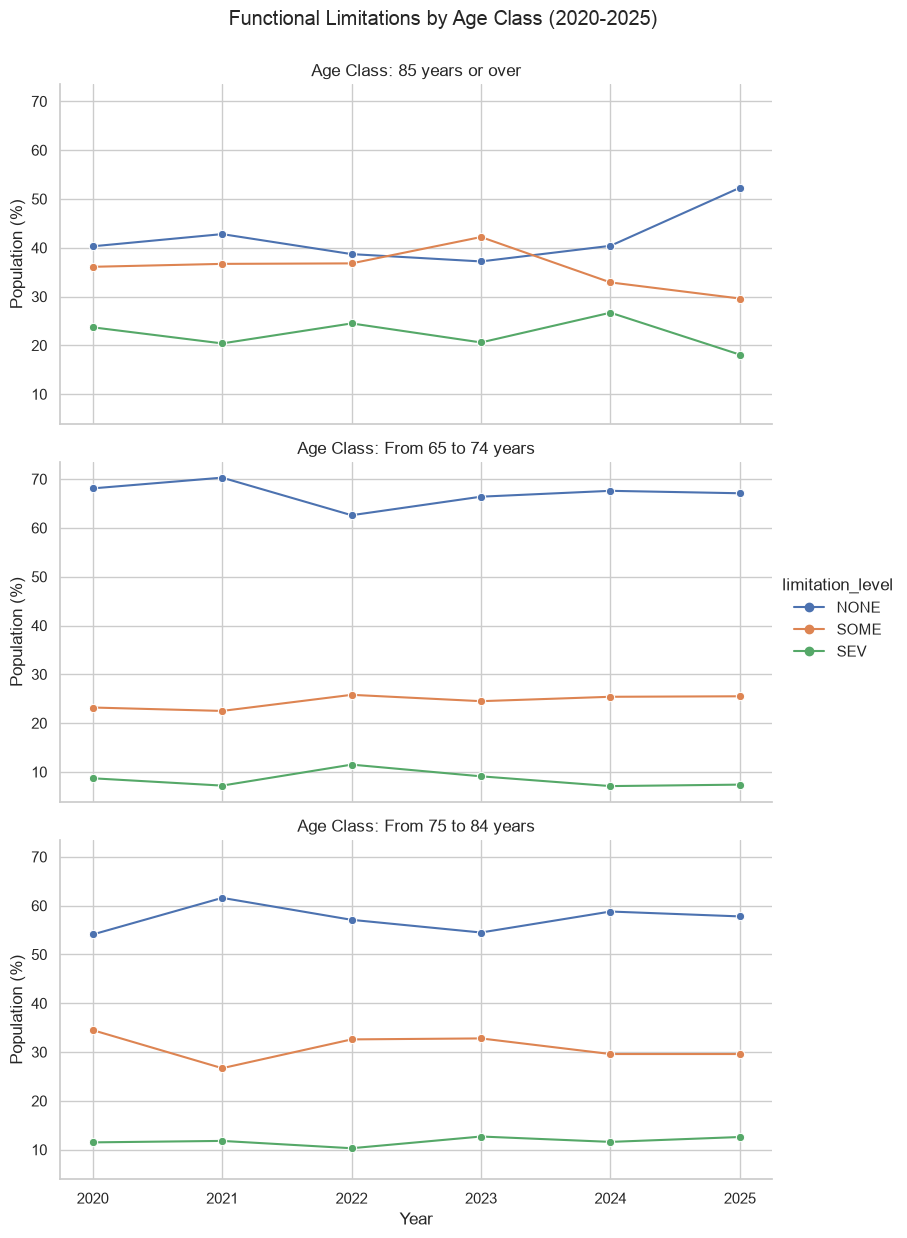

In [37]:
sns.set_theme(style="whitegrid")

functional_long = functional_limitations_comparison.melt(
    id_vars=['time_period', 'age_class'],
    value_vars=['NONE', 'SOME', 'SEV'],
    var_name='limitation_level',
    value_name='percentage'
)

g = sns.relplot(
    data=functional_long,
    x='time_period',
    y='percentage',
    hue='limitation_level',
    col='age_class',
    kind='line',
    marker='o',
    col_wrap=1,
    height=4,
    aspect=2
)

g.set_axis_labels("Year", "Population (%)")
g.set_titles("Age Class: {col_name}")
g.fig.suptitle('Functional Limitations by Age Class (2020-2025)', y=1.03)


plt.show()

### Chart 1 — Functional Limitations by Age Group (2020–2025)

**Purpose:**

To examine how the distribution of functional limitations changed over time across three older age groups in Ireland.

The chart presents three categories:

- NONE: No reported limitations in usual activities.
- SOME: Some reported limitations.
- SEV: Severe reported limitations.

**Key findings:**

In 2025, the 85+ age group recorded the highest proportion of severe limitations (18.1%), compared with 12.6% among people aged 75–84 and 7.4% among those aged 65–74.

The 65–74 age group had the highest proportion of people reporting no limitations (67.1%).

These results indicate differences in the distribution of functional limitations across age groups.

**Interpretation note:** All 2020 observations carry a break-in-series flag. Comparisons involving 2020 should therefore be interpreted with caution.

In [38]:
functional_limitations_comparison['any_limitation'] = functional_limitations_comparison['SOME'] + functional_limitations_comparison['SEV']

functional_limitations_comparison.sort_values(
    ['age_class', 'time_period']
)

level_limit,time_period,age_class,NONE,SEV,SOME,any_limitation
0,2020,85 years or over,40.3,23.7,36.1,59.8
3,2021,85 years or over,42.8,20.4,36.7,57.1
6,2022,85 years or over,38.7,24.5,36.8,61.3
9,2023,85 years or over,37.2,20.6,42.2,62.8
12,2024,85 years or over,40.4,26.7,32.9,59.6
15,2025,85 years or over,52.3,18.1,29.6,47.7
1,2020,From 65 to 74 years,68.1,8.7,23.2,31.9
4,2021,From 65 to 74 years,70.3,7.2,22.5,29.7
7,2022,From 65 to 74 years,62.6,11.5,25.8,37.3
10,2023,From 65 to 74 years,66.4,9.1,24.5,33.6


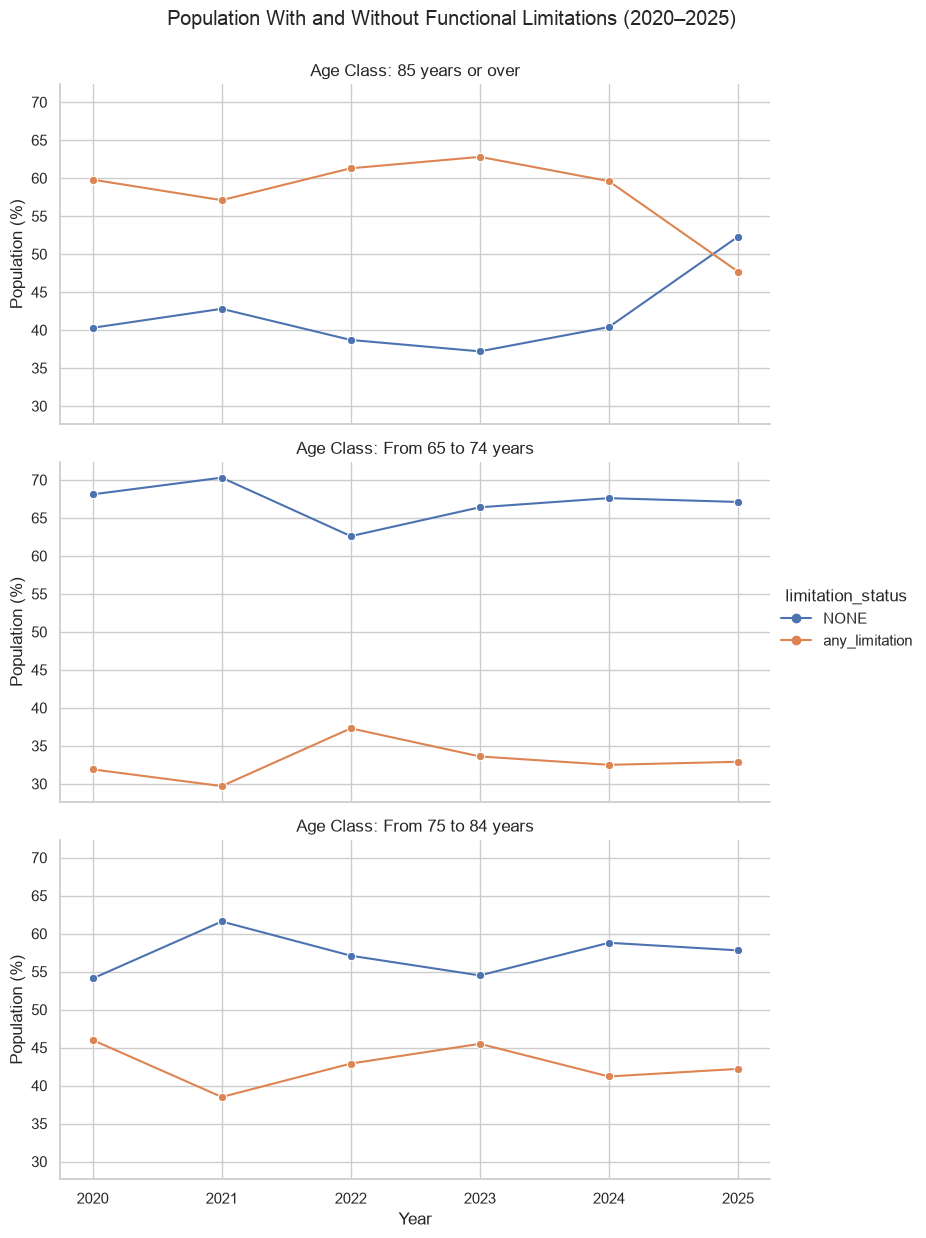

In [39]:
functional_summary = functional_limitations_comparison.melt(
    id_vars=['time_period', 'age_class'],
    value_vars=['NONE', 'any_limitation'],
    var_name='limitation_status',
    value_name='percentage'
)  

g = sns.relplot(
    data=functional_summary,
    x='time_period',
    y='percentage',
    hue='limitation_status',
    col='age_class',
    kind='line',
    marker='o',
    col_wrap=1,
    height=4,
    aspect=2
)

g.set_axis_labels('Year', 'Population (%)')
g.set_titles("Age Class: {col_name}")
g.fig.suptitle(
    'Population With and Without Functional Limitations (2020–2025)',
    y=1.03
)

plt.show()

### Chart 2 — Population With and Without Functional Limitations (2020–2025)

**Purpose:**

To compare the proportion of older people reporting no functional limitations with those reporting at least some limitations.

The chart combines the original Eurostat categories into two indicators:

- NONE: No reported functional limitations.
- ANY LIMITATION: The sum of SOME and SEV.

**Key findings:**

In 2025, 32.9% of people aged 65–74 reported some level of functional limitation. This proportion increased to 42.2% among those aged 75–84 and 47.7% among people aged 85 and over.

The results show that the proportion reporting functional limitations was higher in the older age groups.

This indicator provides a simplified view of functional limitations and helps contextualise potential long-term care needs in Ireland.

**Interpretation note:** Reporting a functional limitation does not necessarily mean that a person requires formal Home Support or Nursing Home care. The 2020 observations also carry a break-in-series flag and should be interpreted with caution.

In [40]:
functional_limitations_comparison['percentage_check'] = (
    functional_limitations_comparison['NONE']
    + functional_limitations_comparison['SOME']
    + functional_limitations_comparison['SEV']
)

functional_limitations_comparison[
    ['time_period', 'age_class', 'percentage_check']
].sort_values(['age_class', 'time_period'])

level_limit,time_period,age_class,percentage_check
0,2020,85 years or over,100.1
3,2021,85 years or over,99.9
6,2022,85 years or over,100.0
9,2023,85 years or over,100.0
12,2024,85 years or over,100.0
15,2025,85 years or over,100.0
1,2020,From 65 to 74 years,100.0
4,2021,From 65 to 74 years,100.0
7,2022,From 65 to 74 years,99.9
10,2023,From 65 to 74 years,100.0


In [41]:
functional_limitations_comparison['percentage_check'].describe()

count     18.000000
mean     100.011111
std        0.058298
min       99.900000
25%      100.000000
50%      100.000000
75%      100.000000
max      100.100000
Name: percentage_check, dtype: float64

In [42]:
functional_limitations_comparison.loc[
    functional_limitations_comparison['percentage_check'].sub(100).abs() > 0.2,
    ['time_period', 'age_class', 'percentage_check']
]

level_limit,time_period,age_class,percentage_check


### Percentage Consistency Validation

A consistency check was performed to verify whether the three functional limitation categories (NONE, SOME and SEV) add up to approximately 100% for each year and age group.

**Validation results:**

- Total observations checked: 18
- Mean percentage sum: 100.01%
- Minimum percentage sum: 99.90%
- Maximum percentage sum: 100.10%
- Standard deviation: 0.058

All observations were within the accepted tolerance of ±0.2 percentage points from 100%.

The small differences are consistent with rounding in the published percentages.

**Conclusion:**

The percentage distributions are consistent across all years and age groups. No adjustments to the original values were necessary.

In [43]:
functional_limitations_comparison['age_group_standardized'] = (
    functional_limitations_comparison['age_class'].replace({
        'From 65 to 74 years': '65–74 years',
        'From 75 to 84 years': '75–84 years',
        '85 years or over': '85 years and over'
    })
)

functional_limitations_comparison[
    ['age_class', 'age_group_standardized']
].drop_duplicates().sort_values('age_group_standardized')

level_limit,age_class,age_group_standardized
1,From 65 to 74 years,65–74 years
2,From 75 to 84 years,75–84 years
0,85 years or over,85 years and over


**Data Transformation — Age Group Standardisation**

A new column, `age_group_standardized`, was created to align the Eurostat age categories with the CSO population age groups.

The original `age_class` column was preserved to maintain the source classification and ensure data traceability.

This approach allows both datasets to be compared using consistent age-group labels without modifying the original source information.

In [44]:
eurostat_analysis = functional_limitations_comparison[
    ['time_period', 'age_group_standardized', 'any_limitation']
].copy()

eurostat_2025 = eurostat_analysis.loc[
    eurostat_analysis['time_period'] == 2025
]

eurostat_2025

level_limit,time_period,age_group_standardized,any_limitation
15,2025,85 years and over,47.7
16,2025,65–74 years,32.9
17,2025,75–84 years,42.2


In [45]:
cso_2025 = age_group_aggregated.loc[
    age_group_aggregated['year'] == 2025
].copy()

cso_2025

,year,age_group_new,population
15,2025,65–74 years,476.5
16,2025,75–84 years,288.7
17,2025,85 years and over,96.0


In [46]:
cso_analysis = age_group_years.reset_index().copy()

cso_analysis = cso_analysis[
    [
        'age_group_new',
        2025,
        'absolute_change',
        'percentage_growth'
    ]
].copy()

cso_analysis = cso_analysis.rename(columns={
    2025: 'population_2025'
})

In [47]:
cso_analysis

year,age_group_new,population_2025,absolute_change,percentage_growth
0,65–74 years,476.5,55.3,13.129155
1,75–84 years,288.7,59.4,25.904928
2,85 years and over,96.0,20.4,26.984127


### Data Integration — CSO and Eurostat

**Objective**

The objective of this step was to combine demographic population estimates from the Central Statistics Office (CSO) with functional limitation indicators from Eurostat.

The integration allows population growth and the prevalence of functional limitations to be analysed together across three older age groups in Ireland.

**Data sources**

- **CSO — PEA01:** Population estimates by age group, sex and year. The analysis uses population estimates for 2020–2025.
- **Eurostat — Functional Limitations:** Data on self-reported limitations in usual activities due to health problems. The analysis uses 2025 observations.

**Preparation before integration**

Before combining the datasets, the age-group categories were standardized to ensure consistent labels.

The original age classifications were preserved in both datasets, and new standardized categories were created where necessary.

The following categories were aligned:

| CSO age group | Eurostat age group | Standardized category |
|---|---|---|
| 65–74 years | From 65 to 74 years | 65–74 years |
| 75–84 years | From 75 to 84 years | 75–84 years |
| 85 years and over | 85 years or over | 85 years and over |

**Integration method**

The Pandas `merge()` method was used to combine the datasets.

The integration was performed using an inner join based on the standardized age-group categories.

A one-to-one validation (`validate='one_to_one'`) was applied to ensure that each age group had exactly one corresponding record in each dataset.

**Indicators included in the integrated dataset**

From CSO:
- Population in 2025.
- Absolute population change between 2020 and 2025.
- Percentage population growth between 2020 and 2025.

From Eurostat:
- Percentage of people reporting some or severe functional limitations in 2025 (`any_limitation`).

**Integration result**

The integration produced three records, one for each standardized age group.

The resulting dataset provides a combined view of population growth and functional limitations among older people in Ireland.

**Methodological considerations**

Population growth and functional limitations were maintained as separate indicators because they measure different statistical concepts.

The CSO population estimates are expressed in thousands of people in the source dataset, while Eurostat values represent percentages.

The integration is based on age-group categories, not individual-level records. Therefore, it does not establish a direct relationship between population growth and individual care needs.

The combined indicators provide demographic context for investigating potential pressures on long-term care services.

In [48]:
demographic_analysis = cso_analysis.merge(
    eurostat_2025,
    left_on='age_group_new',
    right_on='age_group_standardized',
    how='inner',
    validate='one_to_one'
)

demographic_analysis

,age_group_new,population_2025,absolute_change,percentage_growth,time_period,age_group_standardized,any_limitation
0,65–74 years,476.5,55.3,13.129155,2025,65–74 years,32.9
1,75–84 years,288.7,59.4,25.904928,2025,75–84 years,42.2
2,85 years and over,96.0,20.4,26.984127,2025,85 years and over,47.7


In [49]:
demographic_analysis_final = demographic_analysis[
    [
        'age_group_new',
        'population_2025',
        'absolute_change',
        'percentage_growth',
        'any_limitation'
    ]
].copy()

demographic_analysis_final

,age_group_new,population_2025,absolute_change,percentage_growth,any_limitation
0,65–74 years,476.5,55.3,13.129155,32.9
1,75–84 years,288.7,59.4,25.904928,42.2
2,85 years and over,96.0,20.4,26.984127,47.7


### Methodological Consideration — Population Growth and Functional Limitations

Population growth and functional limitations are analysed as separate indicators because they measure different aspects of population ageing.

- **Population growth (CSO):** measures the percentage change in the population of each age group between 2020 and 2025.
- **Any functional limitation (Eurostat):** measures the proportion of people reporting some or severe limitations in usual activities in 2025.

These indicators should not be combined into a single average, as they represent different statistical concepts.

Analysing them together provides a broader understanding of demographic change and functional limitations among older people in Ireland.

### Integration Validation

The integrated dataset was checked to confirm that the CSO and Eurostat records were correctly matched.

Validation checks included:

- Confirming that all three age groups were present.
- Confirming that each age group appeared only once.
- Checking for missing values in the integrated indicators.
- Confirming that the integration produced three records.
- Verifying that the age-group categories matched between both sources.

The one-to-one merge validation was successful.

**Conclusion:**

The integration was completed successfully, producing a dataset with three age groups and the selected demographic and functional limitation indicators.

### Implications for Long-Term Care Planning

The analysis identifies people aged 85 and over as an important group to consider in long-term care planning.

Between 2020 and 2025, this age group experienced population growth of approximately 26.98%. In 2025, 47.7% reported some level of functional limitation, including 18.1% with severe limitations.

These findings suggest potential pressure on long-term care services, including Home Support and Nursing Homes.

The demographic and functional limitation indicators may help inform:

- Future Home Support capacity and service-hour planning.
- The availability of appropriate support for older people living independently.
- Nursing Home capacity planning.
- The allocation of resources according to assessed care needs.

**Important limitation:** Age and self-reported functional limitations alone do not establish an individual's eligibility or priority for care. Decisions about support and service allocation require individual needs assessments and other relevant criteria.

# Demographic Population — Final Conclusion

## Overview

This module examined population ageing in Ireland and the distribution of functional limitations among older people between 2020 and 2025.

The analysis combined two official statistical sources:

- **Central Statistics Office (CSO):** population estimates by age group.
- **Eurostat:** self-reported limitations in usual activities due to health problems.

The original CSO age groups were aggregated into three categories to align with the Eurostat age classifications.

## Key Findings

### 1. Population Growth

All three age groups experienced population growth between 2020 and 2025.

- The 65–74 age group increased by approximately 55,300 people (13.13%).
- The 75–84 age group increased by approximately 59,400 people (25.90%).
- The 85+ age group increased by approximately 20,400 people (26.98%).

Although the 65–74 age group had the largest absolute population increase, the 85+ age group recorded the highest percentage growth.

### 2. Functional Limitations

The Eurostat analysis showed differences in the prevalence of functional limitations across age groups in 2025.

- 32.9% of people aged 65–74 reported some level of functional limitation.
- 42.2% of people aged 75–84 reported some level of functional limitation.
- 47.7% of people aged 85 and over reported some level of functional limitation.

The 85+ age group also recorded the highest proportion of severe limitations, at 18.1%.

### 3. Implications for Long-Term Care

The combined findings highlight the importance of considering both demographic growth and functional limitations when planning long-term care services in Ireland.

The growth of the older population, particularly among people aged 75 and over, together with the higher prevalence of functional limitations in these groups, may increase pressure on services such as Home Support and Nursing Homes.

These findings can help contextualise future service capacity, resource planning and the importance of needs-based support.

However, population age and self-reported functional limitations alone do not determine an individual's need or eligibility for formal care.

## Limitations

- The analysis covers population estimates from 2020 to 2025.
- The Eurostat functional limitation indicator is based on self-reported limitations and does not directly measure demand for formal care.
- All 2020 Eurostat observations contain a break-in-series flag and should be interpreted with caution.


# Conclusão Geral — Demographic Population

## 1. Objetivo da análise

O objetivo deste módulo foi compreender o crescimento da população idosa na Irlanda entre 2020 e 2025 e investigar como as limitações funcionais se distribuem entre diferentes faixas etárias.

Para isso, foram utilizadas duas fontes oficiais:

- **Central Statistics Office (CSO):** estimativas populacionais por faixa etária.
- **Eurostat:** dados sobre limitações nas atividades habituais devido a problemas de saúde, por faixa etária.

A análise combinou informações demográficas e funcionais para compreender melhor as possíveis implicações do envelhecimento populacional para os serviços de cuidados de longa duração na Irlanda.

## 2. Crescimento populacional

Os dados do CSO demonstraram crescimento nas três faixas etárias analisadas entre 2020 e 2025.

| Faixa etária | Aumento absoluto | Crescimento percentual |
|---|---:|---:|
| 65–74 anos | 55.300 | 13,13% |
| 75–84 anos | 59.400 | 25,90% |
| 85 anos ou mais | 20.400 | 26,98% |

A faixa de 65–74 anos apresentou o maior aumento absoluto, com aproximadamente 55.300 pessoas adicionais.

Entretanto, a faixa de 85 anos ou mais apresentou o maior crescimento proporcional, de aproximadamente 26,98%, seguida pela faixa de 75–84 anos, com 25,90%.

Esses resultados demonstram que o crescimento populacional não ocorre de maneira uniforme entre as diferentes faixas etárias.

## 3. Limitações funcionais

A análise dos dados do Eurostat permitiu observar a proporção de pessoas que relataram limitações nas atividades habituais em 2025.

| Faixa etária | Sem limitações | Algumas limitações | Limitações severas |
|---|---:|---:|---:|
| 65–74 anos | 67,1% | 25,5% | 7,4% |
| 75–84 anos | 57,8% | 29,6% | 12,6% |
| 85 anos ou mais | 52,3% | 29,6% | 18,1% |

Ao combinar as categorias SOME e SEV, identificamos que:

- 32,9% das pessoas de 65–74 anos relataram alguma limitação funcional.
- 42,2% das pessoas de 75–84 anos relataram alguma limitação funcional.
- 47,7% das pessoas de 85 anos ou mais relataram alguma limitação funcional.

A faixa de 85 anos ou mais apresentou a maior proporção de limitações funcionais, incluindo a maior proporção de limitações severas.

Os resultados indicam uma diferença na distribuição das limitações funcionais entre as faixas etárias analisadas.

## 4. Integração dos resultados

A integração dos dados do CSO e do Eurostat permitiu analisar conjuntamente o crescimento populacional e a prevalência de limitações funcionais.

A faixa de 85 anos ou mais apresentou simultaneamente:

- O maior crescimento populacional proporcional entre 2020 e 2025: 26,98%.
- A maior proporção de pessoas com alguma limitação funcional em 2025: 47,7%.
- A maior proporção de limitações severas em 2025: 18,1%.

A faixa de 75–84 anos também apresentou crescimento populacional expressivo, de 25,90%, e 42,2% de pessoas com alguma limitação funcional.

Esses resultados destacam a importância de considerar as faixas etárias mais avançadas no planejamento dos serviços de cuidados de longa duração.

## 5. Implicações para os cuidados de longa duração

Os resultados podem contribuir para compreender possíveis pressões futuras sobre serviços como Home Support e Nursing Homes.

O crescimento da população idosa, combinado com a maior prevalência de limitações funcionais nas faixas etárias mais avançadas, pode ter implicações para:

- Planejamento da capacidade dos serviços de Home Support.
- Disponibilidade de horas de apoio domiciliar.
- Planejamento da capacidade dos Nursing Homes.
- Organização de diferentes níveis de suporte.
- Planejamento e distribuição de recursos conforme as necessidades avaliadas.

Entretanto, idade e limitações funcionais autorrelatadas não determinam automaticamente a necessidade, elegibilidade ou prioridade individual para receber cuidados formais. Essas decisões dependem de avaliações individuais e de outros critérios relevantes.

## 6. Limitações da análise

Algumas limitações precisam ser consideradas na interpretação dos resultados:

- A análise populacional abrange o período de 2020 a 2025.
- Os dados do Eurostat representam limitações funcionais autorrelatadas, não a demanda efetiva por serviços de Home Support ou Nursing Homes.
- Todas as observações do Eurostat referentes a 2020 possuem a flag `b`, indicando quebra na série temporal. Portanto, comparações envolvendo 2020 exigem cautela.
- Pequenas diferenças na soma das categorias funcionais são compatíveis com o arredondamento dos percentuais publicados.
- O crescimento populacional não significa necessariamente um aumento proporcional da necessidade de cuidados formais.
- A análise não estabelece uma relação causal entre idade, limitações funcionais e demanda por serviços.

## 7. Conclusão

A análise demonstrou que a população idosa da Irlanda cresceu entre 2020 e 2025, com destaque para o crescimento proporcional das faixas etárias de 75–84 anos e 85 anos ou mais.

Ao mesmo tempo, os dados de limitações funcionais demonstraram maior prevalência de limitações nas faixas etárias mais avançadas.

A combinação desses resultados destaca a importância de compreender não apenas o crescimento da população idosa, mas também suas condições funcionais ao investigar os desafios futuros dos cuidados de longa duração na Irlanda.

O módulo Demographic Population fornece, portanto, uma base para a próxima etapa do projeto: investigar como a oferta de serviços de Home Support responde às necessidades e às pressões observadas no sistema irlandês de cuidados de longa duração.